In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing

In [6]:
stocks=pd.read_csv('Stock_Prices.csv')
stocks.head()

,Date,AAPL.Open,AAPL.High,AAPL.Low,AAPL.Close,AAPL.Volume,AAPL.Adjusted,dn,mavg,up,direction
0,2015-02-17,127.489998,128.880005,126.919998,127.830002,63152400,122.905254,106.741052,117.927667,129.114281,Increasing
1,2015-02-18,127.629997,128.779999,127.449997,128.720001,44891700,123.760965,107.842423,118.940333,130.038244,Increasing
2,2015-02-19,128.479996,129.029999,128.330002,128.449997,37362400,123.501363,108.894245,119.889167,130.884089,Decreasing
3,2015-02-20,128.619995,129.500000,128.050003,129.500000,48948400,124.510914,109.785449,120.763500,131.741551,Increasing
4,2015-02-23,130.020004,133.000000,129.660004,133.000000,70974100,127.876074,110.372516,121.720167,133.067817,Increasing


In [8]:
#convert the date into datetime format
stocks['Date']=pd.to_datetime(stocks['Date'])
stocks=stocks.sort_values('Date')
stocks=stocks.set_index('Date')

<Axes: xlabel='Date'>

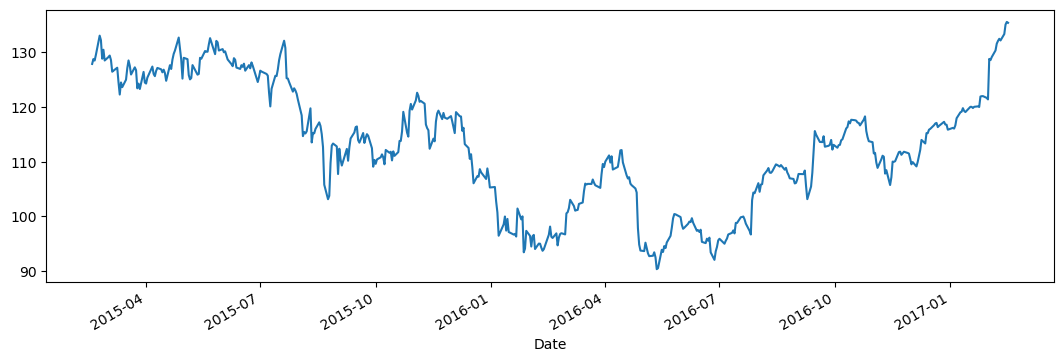

In [12]:
#plot historical closing price
stocks['AAPL.Close'].plot(figsize=(13,4)) 

<Axes: xlabel='Date'>

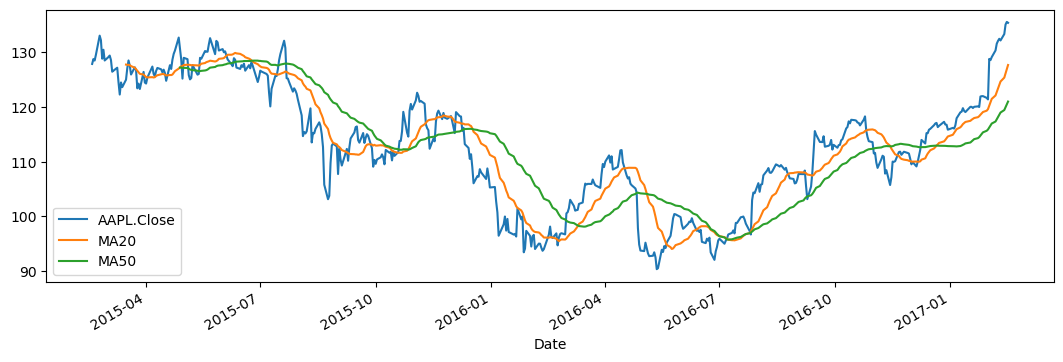

In [14]:
#calculate the plot movinng averages 
stocks['MA20']=stocks['AAPL.Close'].rolling(20).mean()
stocks['MA50']=stocks['AAPL.Close'].rolling(50).mean()

stocks[['AAPL.Close','MA20','MA50']].plot(figsize=(13,4))

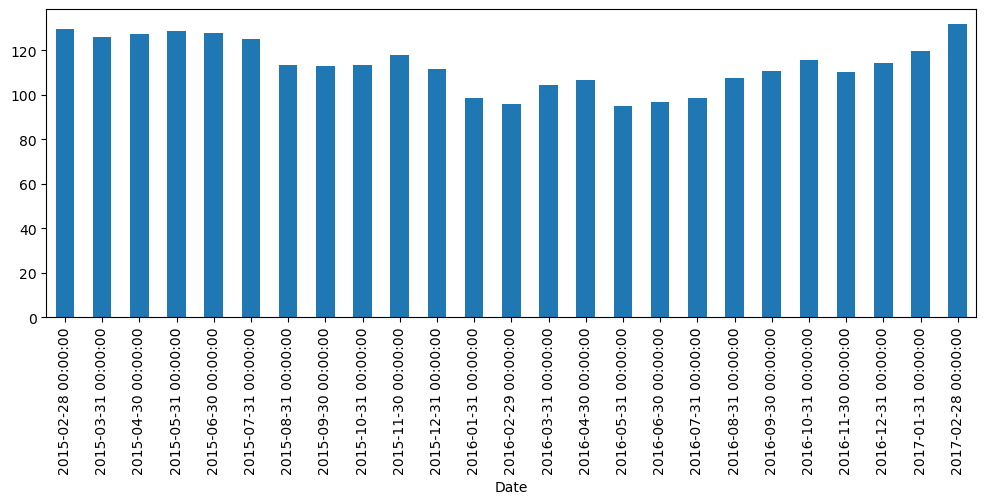

In [18]:
#Seasonality analysis 
monthly=stocks['AAPL.Close'].resample('ME').mean()
monthly.plot(kind='bar',figsize=(12,4))
plt.show()

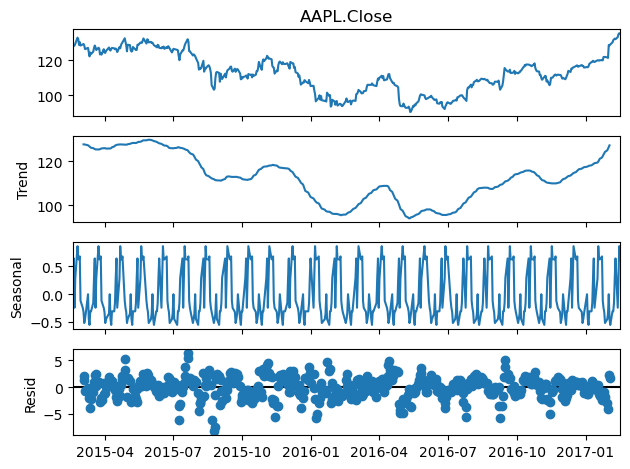

In [22]:
#seasonal decomp
res=seasonal_decompose(stocks['AAPL.Close'],model='additive',period=20)
res.plot()
plt.show()

             AAPL.Close  AAPL.Volume
AAPL.Close     1.000000     0.023473
AAPL.Volume    0.023473     1.000000


<Axes: xlabel='AAPL.Close', ylabel='AAPL.Volume'>

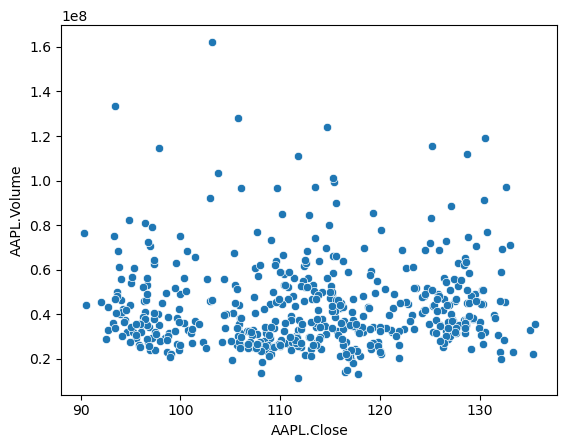

In [24]:
#corr between stock price and volume
print(stocks[['AAPL.Close','AAPL.Volume']].corr())

sns.scatterplot(x=stocks['AAPL.Close'],y=stocks['AAPL.Volume'])

C:\Users\asus\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\asus\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\asus\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:836: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


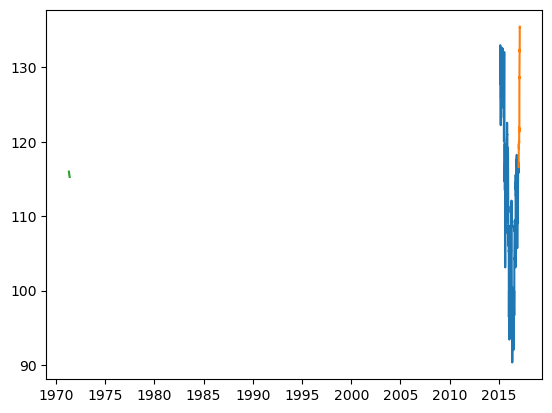

In [30]:
#Forecast future stock prices using exponential Smoothing
train=stocks['AAPL.Close'][:-30]
test=stocks['AAPL.Close'][-30:]

model=ExponentialSmoothing(train,trend='add').fit()
forecast=model.forecast(30)
plt.plot(train, label='Training Data')
plt.plot(test, label='Actual Price')
plt.plot(forecast, label='Forecast')
plt.show()